# Regressão Linear

In [2]:
%pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Importando as Bibliotecas

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## Carregamento dos dados do CSV

In [4]:
try:
    dados = np.loadtxt('dataset.csv', delimiter=',', skiprows=1)
except FileNotFoundError:
    print("Erro: Arquivo 'dataset.csv' não encontrado")
    print("Por favor, crie o arquivo ou execute o script para gerá-lo")
    exit()

print(dados)

[[ 50. 150.]
 [ 60. 200.]
 [ 70. 250.]
 [ 80. 300.]
 [ 90. 350.]
 [100. 400.]
 [110. 420.]
 [120. 450.]
 [130. 470.]
 [140. 500.]]


## Separando de dados de X e Y

In [5]:
x = dados[:,0]
y = dados[:,1]

print(x)
print(y)

[ 50.  60.  70.  80.  90. 100. 110. 120. 130. 140.]
[150. 200. 250. 300. 350. 400. 420. 450. 470. 500.]


In [6]:
x = x.reshape(-1,1)
y = y.reshape(-1,1)

print("X: ",x)
print("y: ",y)

X:  [[ 50.]
 [ 60.]
 [ 70.]
 [ 80.]
 [ 90.]
 [100.]
 [110.]
 [120.]
 [130.]
 [140.]]
y:  [[150.]
 [200.]
 [250.]
 [300.]
 [350.]
 [400.]
 [420.]
 [450.]
 [470.]
 [500.]]


## Caalculando "a" e "b"

In [7]:
x_mean = np.mean(x)
y_mean = np.mean(y)

print("Media de X",x_mean)
print("media de y", y_mean)

Media de X 95.0
media de y 349.0


## DF Predict

In [8]:
def predict(X_novo,_m,_b):
    return _m * X_novo + _b

O modelo tem um bom ajuste de dados


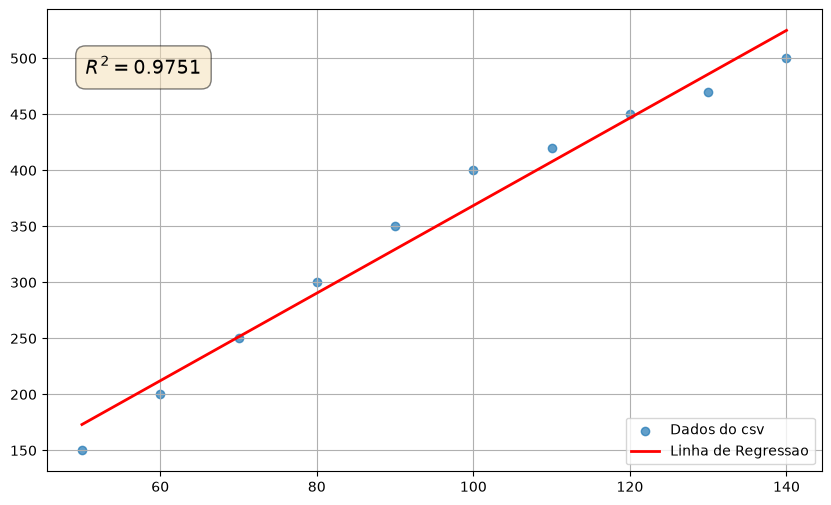

In [9]:
n = len(x)
numerador = np.sum((x - x_mean) * (y - y_mean))
denominador = np.sum((x - x_mean)**2)

m = numerador / denominador
b = y_mean - (m * x_mean)

y_pred = m * x + b

sqr = np.sum((y - y_pred)**2)
sqt = np.sum((y - y_mean)**2)

r2 = 1 - (sqr / sqt)

if r2 > 0.75:
    print("O modelo tem um bom ajuste de dados")
elif r2 > 0.5:
    print("O modelo tem um ajuste moderado")

x_line = np.array([x.min(), x.max()])
y_line = m * x_line + b

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='Dados do csv', alpha=0.7)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Linha de Regressao')

# Correções aplicadas aqui (transform e .4f)
plt.text(0.05, 0.9, f'$R^2 = {r2:.4f}$', transform=plt.gca().transAxes, 
         fontsize=14, verticalalignment='top', 
         bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

plt.legend()
plt.grid(True)
plt.show()